In [1]:
import numpy as np
import matplotlib.pyplot as plt
from zaklj_plast_EB import *
from alignAxes import *
from timeit import default_timer as timer

plt.style.use('aljaz')


Bad key mathtext.bfit in file /home/ravni/.config/matplotlib/stylelib/aljaz.mplstyle, line 353 ('mathtext.bfit: sans:italic:bold')
You probably need to get an updated matplotlibrc file from
https://github.com/matplotlib/matplotlib/blob/v3.7.2/lib/matplotlib/mpl-data/matplotlibrc
or from the matplotlib source distribution

Bad key xtick.minor.ndivs in file /home/ravni/.config/matplotlib/stylelib/aljaz.mplstyle, line 503 ('xtick.minor.ndivs:   auto    # number of minor ticks between the major ticks on x-axis')
You probably need to get an updated matplotlibrc file from
https://github.com/matplotlib/matplotlib/blob/v3.7.2/lib/matplotlib/mpl-data/matplotlibrc
or from the matplotlib source distribution

Bad key ytick.minor.ndivs in file /home/ravni/.config/matplotlib/stylelib/aljaz.mplstyle, line 525 ('ytick.minor.ndivs:   auto    # number of minor ticks between the major ticks on y-axis')
You probably need to get an updated matplotlibrc file from
https://github.com/matplotlib/matplotlib/bl

# prikaz nosilca

In [2]:
N=100
Nh=100
KE1='EB'
KE2='TM'
KE3='TG1'
KE4='TG2'
L=100

sol_EB = solver(N, Nh, N_iter=None, tol=1)

sol_EB.elastic=True
sol_EB.KE = KE1
sol_EB.L=L

x=np.linspace(0,sol_EB.L,sol_EB.Nv) #enakomerno razporejena vozlišča
sol_EB.discretization(x)
sol_EB.elastic_solve()
sol_EB.U, sol_EB.Θ = sol_EB.u.reshape(sol_EB.vozlisca.shape).T
xa=x=np.linspace(0,sol_EB.L,1000)
u_ex_EB,phi_ex,M_ex,T_ex=sol_EB.analitično(xa)


sol_T = solver(N, Nh, N_iter=None, tol=1)

sol_T.elastic=True
sol_T.KE = KE2
sol_T.L=L

x=np.linspace(0,sol_T.L,sol_T.Nv) #enakomerno razporejena vozlišča
sol_T.discretization(x)
sol_T.elastic_solve()
sol_T.U, sol_T.Θ = sol_T.u.reshape(sol_T.vozlisca.shape).T
xa=x=np.linspace(0,sol_T.L,1000)
u_ex_T,phi_ex,M_ex,T_ex=sol_T.analitično(xa)


sol_TG1 = solver(N, Nh, N_iter=None, tol=1) #ni očitne razlike med timošenkom

sol_TG1.elastic=True
sol_TG1.KE = KE3
sol_TG1.L=L

x=np.linspace(0,sol_TG1.L,sol_TG1.Nv) #enakomerno razporejena vozlišča
sol_TG1.discretization(x)
sol_TG1.elastic_solve()
sol_TG1.U, sol_TG1.Θ = sol_TG1.u.reshape(sol_TG1.vozlisca.shape).T

sol_TG2 = solver(N, Nh, N_iter=None, tol=1) #ni očitne razlike med timošenkom

sol_TG2.elastic=True
sol_TG2.KE = KE4
sol_TG2.L=L

x=np.linspace(0,sol_TG2.L,sol_TG2.Nv) #enakomerno razporejena vozlišča
sol_TG2.discretization(x)
sol_TG2.elastic_solve()
sol_TG2.U, sol_TG2.Θ = sol_TG2.u.reshape(sol_TG2.vozlisca.shape).T

(<Figure size 300x300 with 2 Axes>,
 <Axes: xlabel='$x$ [mm]', ylabel='$y$ [mm]'>)

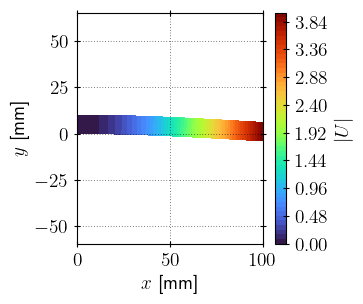

In [3]:
U_all_EB = np.repeat(sol_EB.U,sol_EB.Nh).reshape(sol_EB.Nv,sol_EB.Nh) #poves razširjen na cel prerez
X_cor = np.transpose([-y*sol_EB.Θ for y in sol_EB.y_list]) #popravek zaradi ZASUKA PREREZA
sol_EB.X_defor, sol_EB.Y_defor = sol_EB.X_defor + X_cor, sol_EB.Y_defor + U_all_EB

U_all_TG1 = np.repeat(sol_TG1.U,sol_TG1.Nh).reshape(sol_TG1.Nv,sol_TG1.Nh) #poves razširjen na cel prerez
X_cor = np.transpose([-y*sol_TG1.Θ for y in sol_TG1.y_list]) #popravek zaradi ZASUKA PREREZA
sol_TG1.X_defor, sol_TG1.Y_defor = sol_TG1.X_defor + X_cor, sol_TG1.Y_defor + U_all_TG1

fig,ax=plt.subplots(1,1,figsize=(3,3))
plt.axis('equal')
sol_EB.plot_cross_voz(np.abs(U_all_EB), label='$|U|$', show=False, ax=ax, fig=fig)
# plt.savefig(f'./slike/polje_{sol_EB.KE}_{sol_EB.L}.pdf', bbox_inches='tight')

(<Figure size 450x300 with 2 Axes>,
 <Axes: xlabel='$x$ [mm]', ylabel='$y$ [mm]'>)

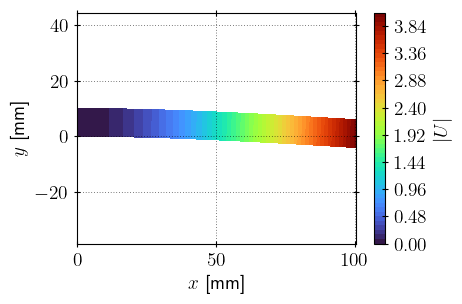

In [4]:
fig,ax=plt.subplots(1,1,figsize=(4.5,3))
plt.axis('equal')
sol_TG1.plot_cross_voz(np.abs(U_all_TG1), label='$|U|$', show=False, ax=ax, fig=fig)
# plt.savefig(f'./slike/polje_{sol_TG1.KE}_{sol_TG1.L}.pdf', bbox_inches='tight')

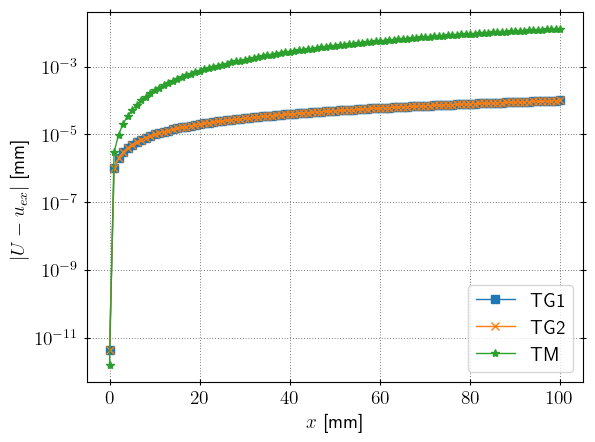

In [5]:
u_ex_T,_,_,_=sol_TG1.analitično()
fig,ax=plt.subplots(1,1)
ax.plot(sol_TG1.vozlisca[:,0], np.abs(sol_TG1.U-u_ex_T), 's-',label=r'TG1')
ax.plot(sol_TG1.vozlisca[:,0], np.abs(sol_TG1.U-u_ex_T), 'x-', label=r'TG2')
ax.plot(sol_TG2.vozlisca[:,0], np.abs(sol_TG2.U-u_ex_T), '*-', label=r'TM')
ax.set_yscale('log')
ax.set_xlabel(r'$x$ [mm]')
ax.set_ylabel(r'$|U-u_{ex}|$ [mm]')
plt.legend()
# plt.savefig(f'./slike/timo.pdf', bbox_inches='tight')

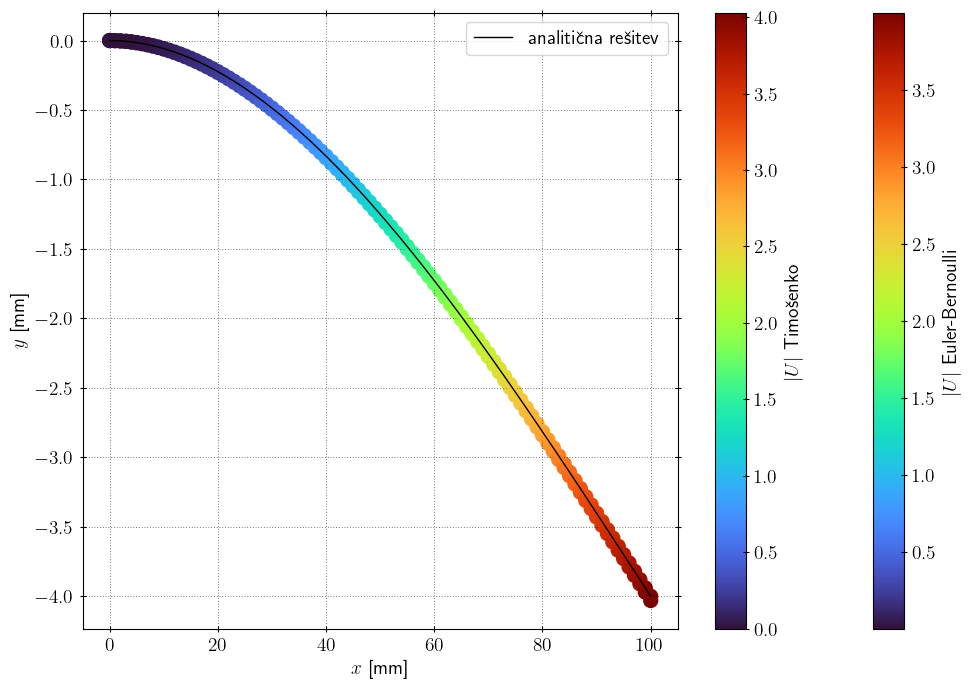

In [6]:
fig,ax=plt.subplots(1,1,figsize=(12,8))
sol_EB.plot_tez_voz(np.abs(sol_EB.U), label=r'$|U|$ Euler-Bernoulli', ax=ax, fig=fig)
sol_T.plot_tez_voz(np.abs(sol_T.U), label=r'$|U|$ Timošenko', ax=ax, fig=fig)
# sol_TG1.plot_tez_voz(np.abs(sol_TG1.U), label=r'$|U|$ '+KE3, ax=ax, fig=fig)
ax.plot(xa, u_ex_EB, '-', c='k', label='analitična rešitev')
# ax.plot(xa, u_ex_T, '-', c='k')
plt.legend()
# plt.savefig(f'./slike/poves_L{L}.pdf', bbox_inches='tight')

Text(0, 0.5, '$|\\Theta-\\Theta_{ex}|$ [rad]')

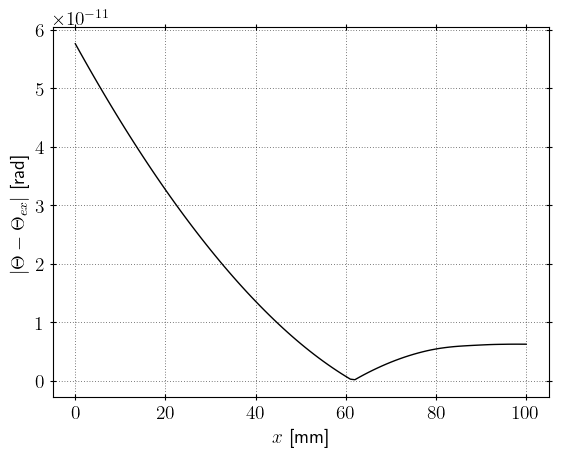

In [7]:
a,e,_,_=sol_EB.analitično()
# plt.plot(sol_EB.vozlisca[:,0], np.abs(sol_EB.U-a), '-',label=r'EB')
plt.plot(sol_EB.vozlisca[:,0], np.abs(sol_EB.Θ-e), 'k-')
plt.xlabel(r'$x$ [mm]')
plt.ylabel(r'$|\Theta-\Theta_{ex}|$ [rad]')
# plt.savefig(f'./slike/zasuk_EB_N1000.pdf', bbox_inches='tight')

## druge obrem

Text(0, 0.5, '$U$ [mm]')

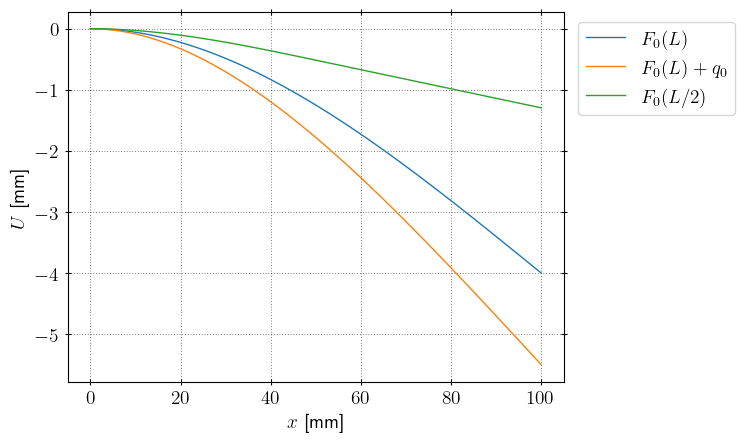

In [101]:
fig,ax=plt.subplots(1,1)
KE='EB'

sol = solver(Ne=100, Nh=100, N_iter=None, tol=1)
sol.elastic=True
sol.KE = KE
sol.RP = [2,0]
sol.RP_F = [0,0,1]
sol.RP_M = [0,0,0]
sol.q0 = 0
sol.discretization()
sol.elastic_solve()
u_ex,phi_ex,M_ex,T_ex=sol.analitično() #le za konzolo!
ax.plot(sol.vozlisca[:,0], sol.U, '-', label='$F_0(L)$')

sol = solver(Ne=100, Nh=100, N_iter=None, tol=1)
sol.elastic=True
sol.KE = KE
sol.RP = [2,0]
sol.RP_F = [0,0,1]
sol.RP_M = [0,0,0]
sol.q0 = 1e-2
sol.discretization()
sol.elastic_solve()
ax.plot(sol.vozlisca[:,0], sol.U, '-', label='$F_0(L) + q_0$')

sol = solver(Ne=100, Nh=100, N_iter=None, tol=1)
sol.elastic=True
sol.KE = KE
sol.RP = [2,0]
sol.RP_F = [0,0,0]
sol.RP_M = [0,1,0]
sol.F0=0
sol.M0=1
sol.q0 = 0
sol.discretization()
sol.elastic_solve()
ax.plot(sol.vozlisca[:,0], sol.U, '-', label='$F_0(L/2)$')

plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
ax.set_xlabel(r'$x$ [mm]')
ax.set_ylabel(r'$U$ [mm]')
# plt.savefig(f'./slike/poves_RP.pdf', bbox_inches='tight')

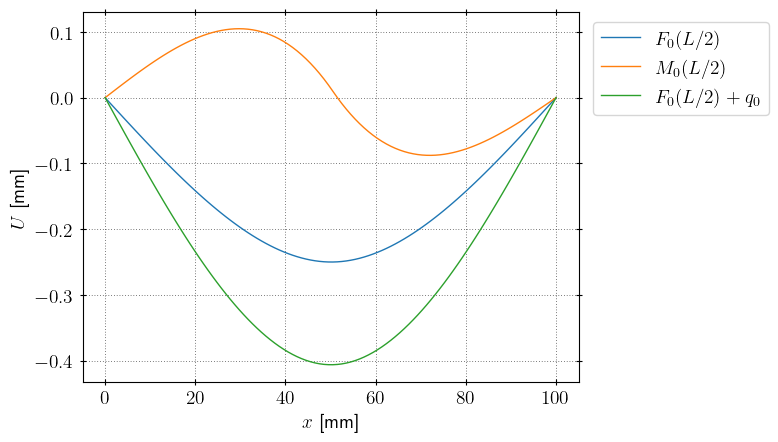

In [ ]:
fig,ax=plt.subplots(1,1)

sol = solver(Ne=101, Nh=100, N_iter=None, tol=1)
sol.elastic=True
sol.KE = KE
sol.RP = [1,1]
sol.RP_F = [0,1,0]
sol.RP_M = [0,0,0]
sol.q0 = 0
sol.discretization()
sol.elastic_solve()
ax.plot(sol.vozlisca[:,0], sol.U, '-', label='$F_0(L/2)$')

sol = solver(Ne=101, Nh=100, N_iter=None, tol=1)
sol.elastic=True
sol.KE = KE
sol.RP = [1,1]
sol.RP_F = [0,0,0]
sol.RP_M = [0,1,0]
sol.M0 = 100
sol.discretization()
sol.elastic_solve()
ax.plot(sol.vozlisca[:,0], sol.U, '-', label='$M_0(L/2)$')

sol = solver(Ne=101, Nh=100, N_iter=None, tol=1)
sol.elastic=True
sol.KE = KE
sol.RP = [1,1]
sol.RP_F = [0,1,0]
sol.RP_M = [0,0,0]
sol.q0 = 1e-2
sol.discretization()
sol.elastic_solve()
ax.plot(sol.vozlisca[:,0], sol.U, '-', label='$F_0(L/2)+q_0$')

plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
ax.set_xlabel(r'$x$ [mm]')
ax.set_ylabel(r'$U$ [mm]')
# plt.savefig(f'./slike/poves_clenki.pdf', bbox_inches='tight')

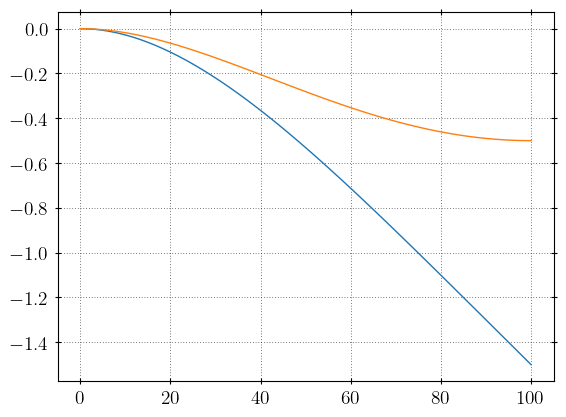

In [10]:
fig,ax=plt.subplots(1,1)

sol = solver(Ne=100, Nh=100, N_iter=None, tol=1)
sol.elastic=True
sol.KE = 'EB'
sol.RP = [2,0]
sol.RP_F = [0,0,0]
sol.RP_M = [0,0,0]
sol.M0=0
sol.F0=0
sol.q0 = 1e-2
sol.discretization()
sol.elastic_solve()
uex,_,_,_=sol.analitično() #le za konzolo!
ax.plot(sol.vozlisca[:,0], sol.U, '-', label='$M_0(L) + q_0$')
ax.plot(sol.vozlisca[:,0], uex, '-', label='analitična rešitev')

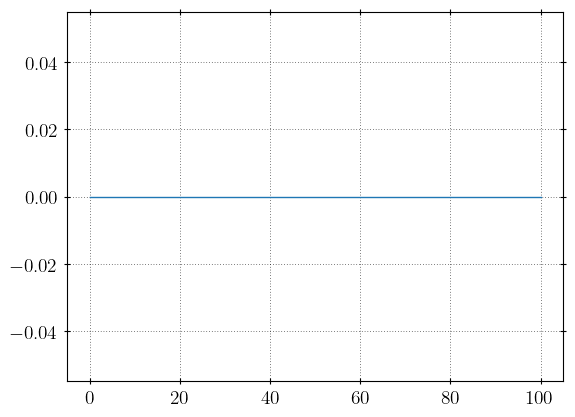

In [37]:
fig,ax=plt.subplots(1,1)

sol = solver(Ne=100, Nh=100, N_iter=None, tol=1)
sol.elastic=True
sol.KE = 'EB'
sol.RP = [1,1]
sol.RP_F = [0,0,0]
sol.RP_M = [0,0,0]
sol.M0=10
sol.F0=1
sol.q0 = 0
sol.discretization()
sol.elastic_solve()
ax.plot(sol.vozlisca[:,0], sol.U, '-', label='$M_0(L) + q_0$')


# konvergenca

In [11]:
N_list = np.logspace(1,4,50).astype(int) #št. vozlišč za konvergenco
Nh = 10 #št. točk po višini prereza
KE2 = 'TG2' #izbira KE (EB=nosilec Euler-Bernoulli, TG1,TG2,TM-oblike za Timošenko)

u_err = np.zeros_like(N_list, dtype=float)
phi_err = np.zeros_like(N_list, dtype=float)
M_err = np.zeros_like(N_list, dtype=float)
T_err = np.zeros_like(N_list, dtype=float)
u_max=np.zeros_like(N_list, dtype=float)
time = np.zeros_like(N_list, dtype=float)

timer()
for i, N in enumerate(N_list):
    t1=timer()
    sol = solver(N, Nh, N_iter=None, tol=1)
    sol.elastic=True
    sol.KE = KE2
    x=np.linspace(0,sol.L,sol.Nv) #enakomerno razporejena vozlišča
    sol.discretization(x)
    # sol.global_loop()
    sol.elastic_solve()
    sol.U, sol.Θ = sol.u.reshape(sol.vozlisca.shape).T
    t2=timer()
    time[i] = t2-t1    
    u_ex,phi_ex,M_ex,T_ex=sol.analitično()

    u_max[i] = abs(np.max(np.abs(u_ex))-np.max(np.abs(sol.U)))

    # u_err[i] = np.linalg.norm(sol.U)
    # phi_err[i] = np.linalg.norm(sol.Θ)
    # M_err[i] = np.linalg.norm(sol.M)
    # T_err[i] = np.linalg.norm(sol.T)

    # u_err[i] = np.linalg.norm(u_ex-sol.U)
    # phi_err[i] = np.linalg.norm(phi_ex-sol.Θ)
    # M_err[i] = np.linalg.norm(M_ex-sol.M)
    # T_err[i] = np.linalg.norm(T_ex-sol.T)
    
    u_err[i] = np.linalg.norm(u_ex-sol.U)/np.linalg.norm(u_ex)
    phi_err[i] = np.linalg.norm(phi_ex-sol.Θ)/np.linalg.norm(phi_ex)
    M_err[i] = np.linalg.norm(M_ex-sol.M)/np.linalg.norm(M_ex)
    T_err[i] = np.linalg.norm(T_ex-sol.T)/np.linalg.norm(T_ex)

/home/ravni/Desktop/Modelska_II/zaklj_nal/zaklj_plast_EB.py:112: RuntimeWarning: overflow encountered in power
  u_eb = self.load_incr * self.F0*x**2/(6*self.E*self.I)*(x-3*self.L) - self.M0*x**2/(2*self.E*self.I) - self.q0*self.L**x**2/(6*self.E*self.I)*(x-3*self.L)
/home/ravni/Desktop/Modelska_II/zaklj_nal/zaklj_plast_EB.py:112: RuntimeWarning: invalid value encountered in multiply
  u_eb = self.load_incr * self.F0*x**2/(6*self.E*self.I)*(x-3*self.L) - self.M0*x**2/(2*self.E*self.I) - self.q0*self.L**x**2/(6*self.E*self.I)*(x-3*self.L)


KeyboardInterrupt: 

In [149]:
KE1 = 'TG1' #izbira KE (EB=nosilec Euler-Bernoulli, TG1,TG2,TM-oblike za Timošenko)

u_err_TG1 = np.zeros_like(N_list, dtype=float)
phi_err_TG1 = np.zeros_like(N_list, dtype=float)
M_err_TG1 = np.zeros_like(N_list, dtype=float)
T_err_TG1 = np.zeros_like(N_list, dtype=float)
u_max_TG1=np.zeros_like(N_list, dtype=float)
time_TG1 = np.zeros_like(N_list, dtype=float)

for i, N in enumerate(N_list):
    t1=timer()
    sol = solver(N, Nh, N_iter=None, tol=1)
    sol.elastic=True
    sol.KE = KE1
    x=np.linspace(0,sol.L,sol.Nv) #enakomerno razporejena vozlišča
    sol.discretization(x)
    sol.elastic_solve()
    sol.U, sol.Θ = sol.u.reshape(sol.vozlisca.shape).T
    t2=timer()
    time_TG1[i] = t2-t1

    u_ex,phi_ex,M_ex,T_ex=sol.analitično()
    u_max_TG1[i] = abs(np.max(np.abs(u_ex))-np.max(np.abs(sol.U)))   
    u_err_TG1[i] = np.linalg.norm(u_ex-sol.U)/np.linalg.norm(u_ex)
    phi_err_TG1[i] = np.linalg.norm(phi_ex-sol.Θ)/np.linalg.norm(phi_ex)
    M_err_TG1[i] = np.linalg.norm(M_ex-sol.M)/np.linalg.norm(M_ex)
    T_err_TG1[i] = np.linalg.norm(T_ex-sol.T)/np.linalg.norm(T_ex)

(-2.005591054408238, 0.12628375549113685)

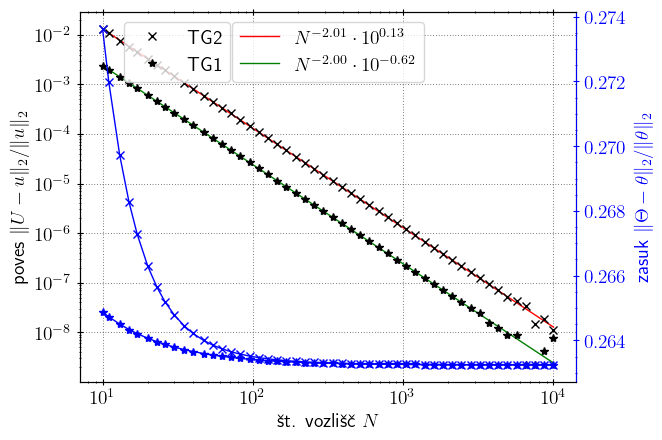

In [154]:
k,n=linfit(np.log10(N_list), np.log10(u_err))
ktg1,ntg1=linfit(np.log10(N_list), np.log10(u_err_TG1))

fig,ax=plt.subplots()
ax.loglog(N_list, N_list**k * 10**n, 'r-', label=f'$N^{{{k:.2f}}}\cdot 10^{{{n:.2f}}}$')
ax.loglog(N_list, N_list**ktg1 * 10**ntg1, 'g-', label=f'$N^{{{ktg1:.2f}}}\cdot 10^{{{ntg1:.2f}}}$')
l1=ax.loglog(N_list, u_err, 'kx')
l2=ax.loglog(N_list, u_err_TG1, 'k*')
ax.minorticks_on()
# ax.grid(which='both', axis='both')
ax.set_xlabel('št. vozlišč $N$')
ax.set_ylabel(r'poves $\|U-u\|_2/\|u\|_2$')
ax.grid(True, which='major')
ax.legend(loc='upper center')

ax1 = ax.twinx()
ax1.plot(N_list, phi_err, 'bx-', label='$\phi$')
ax1.plot(N_list, phi_err_TG1, 'b*-', label='$\phi$')
ax1.set_ylabel(r'zasuk $\|\Theta-\theta\|_2/\|\theta\|_2$', color='b')
# ax1.set_yscale('log')
ax1.minorticks_on()
ax1.tick_params(axis='y', which='both', colors='b')
ax1.spines['right'].set_color('b')
# ax1.spines['right'].set_linewidth(1)
# ax1.grid(which='both', axis='both')
ax1.grid(False)
ax1.legend([l1[0],l2[0]], [KE2,KE1], loc='upper left', bbox_to_anchor=(0.07,1))
# alignYaxes([ax,ax1], [np.max(u_err), 0.2648])
# plt.savefig('./slike/napaka_konv_EBTM.pdf', bbox_inches='tight')
k,n

Text(0.5, 0, 'št. vozlišč $N$')

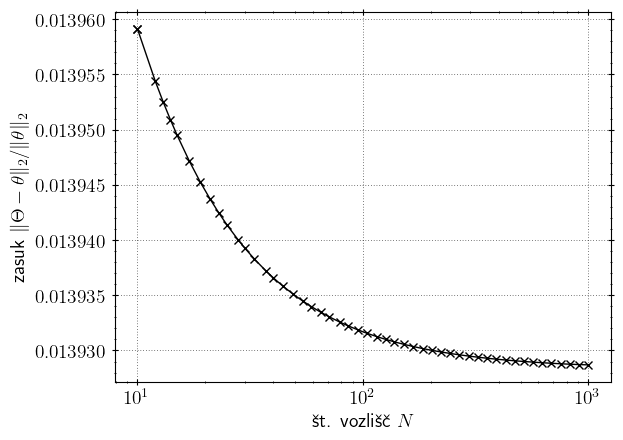

In [53]:
fig,ax1 = plt.subplots()
ax1.plot(N_list, phi_err, 'kx-', label='$\phi$') #le ta eb
ax1.set_ylabel(r'zasuk $\|\Theta-\theta\|_2/\|\theta\|_2$')
ax1.set_xscale('log')
# ax1.set_yscale('log')
ax1.minorticks_on()
ax1.set_xlabel('št. vozlišč $N$')
# plt.savefig('./slike/napaka_konv_phi_EB.pdf', bbox_inches='tight')

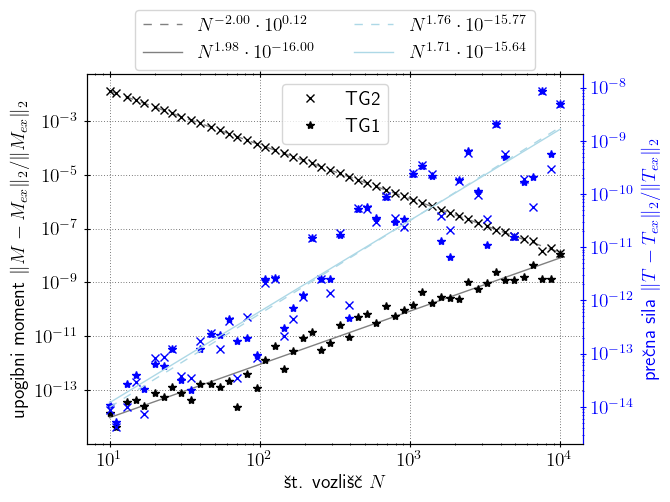

In [ ]:
k,n=linfit(np.log10(N_list), np.log10(M_err))
kt,nt=linfit(np.log10(N_list), np.log10(T_err))
ktm,ntm=linfit(np.log10(N_list), np.log10(M_err_TG1))
kttm,nttm=linfit(np.log10(N_list), np.log10(T_err_TG1))

fig,ax=plt.subplots()
l1=ax.loglog(N_list, N_list**k * 10**n, '--', label=f'$N^{{{k:.2f}}}\cdot 10^{{{n:.2f}}}$', c='gray')
l11=ax.loglog(N_list, N_list**ktm * 10**ntm, '-', label=f'$N^{{{ktm:.2f}}}\cdot 10^{{{ntm:.2f}}}$', c='gray')
t1=ax.loglog(N_list, M_err, 'kx')
t2=ax.loglog(N_list, M_err_TG1, 'k*')
ax.minorticks_on()
# ax.grid(which='both', axis='both')
ax.set_xlabel('št. vozlišč $N$')
ax.set_ylabel(r'upogibni moment $\|M-M_{ex}\|_2/\|M_{ex}\|_2$')
ax.grid(True, which='major')

ax1 = ax.twinx()
ax1.loglog(N_list, T_err, 'bx', label='$\phi$')
ax1.loglog(N_list, T_err_TG1, 'b*', label='$\phi$')
ax1.set_ylabel(r'prečna sila $\|T-T_{ex}\|_2/\|T_{ex}\|_2$', color='b')
l2=ax1.loglog(N_list, N_list**kt * 10**nt, '--', label=f'$N^{{{k:.2f}}}\cdot 10^{{{n:.2f}}}$', c='lightblue')
l22=ax1.loglog(N_list, N_list**kttm * 10**nttm, '-', label=f'$N^{{{kttm:.2f}}}\cdot 10^{{{nttm:.2f}}}$', c='lightblue')
ax1.minorticks_on()
ax1.tick_params(axis='y', which='both', colors='b')
ax1.spines['right'].set_color('b')
# ax1.spines['right'].set_linewidth(1)
# ax1.grid(which='both', axis='both')
ax1.grid(False)
ax.legend((l1[0], l11[0], l2[0], l22[0]), (f'$N^{{{k:.2f}}}\cdot 10^{{{n:.2f}}}$', f'$N^{{{ktm:.2f}}}\cdot 10^{{{ntm:.2f}}}$', f'$N^{{{kt:.2f}}}\cdot 10^{{{nt:.2f}}}$', f'$N^{{{kttm:.2f}}}\cdot 10^{{{nttm:.2f}}}$'), loc='upper center', ncols=2, bbox_to_anchor=(0.5,1.2))
ax1.legend([t1[0],t2[0]], [KE2,KE1], loc='upper center', bbox_to_anchor=(0.5,1))
# plt.savefig('./slike/napaka_konv_MT.pdf', bbox_inches='tight')

Text(0, 0.5, 'čas [s]')

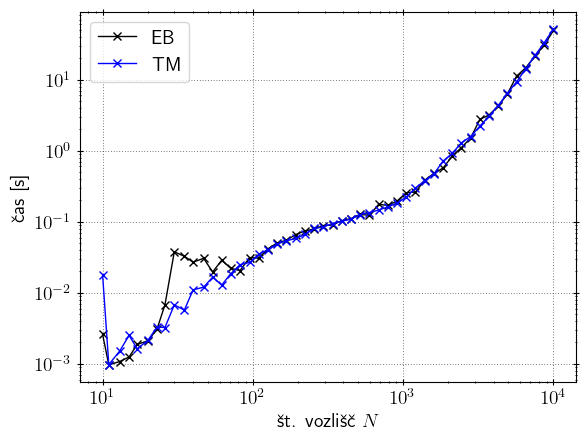

In [158]:
plt.loglog(N_list, time, 'kx-', label='EB')
plt.loglog(N_list, time_TG1, 'bx-', label='TM')
plt.xlabel('št. vozlišč $N$')
plt.legend()
plt.ylabel('čas [s]')
# plt.savefig('./slike/cas_konv_EBTM.pdf', bbox_inches='tight')

In [8]:
# Nh ne vpliva na rešitev!
N_list = np.linspace(1, 100, 30).astype(int) #št. vozlišč po višini prereza
N = 10 #št. vozlišč
KE = 'TG1' #izbira KE (EB=nosilec Euler-Bernoulli, TG1,TG2,TM-oblike za Timošenko)

u_err = np.zeros_like(N_list, dtype=float)
phi_err = np.zeros_like(N_list, dtype=float)
M_err = np.zeros_like(N_list, dtype=float)
T_err = np.zeros_like(N_list, dtype=float)
u_max=np.zeros_like(N_list, dtype=float)
time= np.zeros_like(N_list, dtype=float)

for i, Nh in enumerate(N_list):
    t1=timer()
    sol = solver(N, Nh, N_iter=None, tol=1)
    sol.elastic=True
    sol.KE = KE
    x=np.linspace(0,sol.L,sol.Nv) #enakomerno razporejena vozlišča
    sol.discretization(x)
    sol.elastic_solve()
    sol.U, sol.Θ = sol.u.reshape(sol.vozlisca.shape).T
    t2=timer()
    time[i] = t2-t1
    
    u_ex,phi_ex,M_ex,T_ex=sol.analitično()    
    u_err[i] = np.linalg.norm(u_ex-sol.U)/np.linalg.norm(u_ex)
    phi_err[i] = np.linalg.norm(phi_ex-sol.Θ)/np.linalg.norm(phi_ex)
    M_err[i] = np.linalg.norm(M_ex-sol.M)/np.linalg.norm(M_ex)
    T_err[i] = np.linalg.norm(T_ex-sol.T)/np.linalg.norm(T_ex)
    u_max[i] = abs(np.max(np.abs(u_ex))-np.max(np.abs(sol.U)))

/home/ravni/Desktop/Modelska_II/zaklj_nal/zaklj_plast_EB.py:72: RuntimeWarning: divide by zero encountered in scalar divide
  self.hy = self.h/(self.Nh-1) # višina deljenja prereza
/home/ravni/Desktop/Modelska_II/zaklj_nal/zaklj_plast_EB.py:255: RuntimeWarning: invalid value encountered in scalar multiply
  for i in range(self.Nh): self.X_defor[:,i], self.Y_defor[:,i] = self.vozlisca[:,0], self.vozlisca[:,1] + self.hy*i #sym


Text(0, 0.5, 'čas [s]')

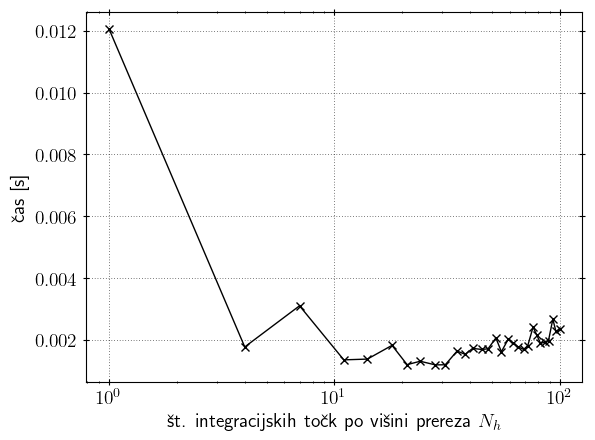

In [9]:
plt.semilogx(N_list, time, 'kx-', label='u')
plt.xlabel('št. integracijskih točk po višini prereza $N_h$')
plt.ylabel('čas [s]')

## zgoščevanje KE

In [103]:
sol = solver(Ne=50, Nh=100, N_iter=None, tol=1)

sol.elastic=True
sol.KE = 'EB'
# sol.L=100

x = sol.zgostitev1(ratio=5)
# x = sol.zgostitev2()
# x=np.linspace(0,sol.L,sol.Nv) #enakomerno razporejena vozlišča

sol.discretization(x)
sol.elastic_solve()
sol.U, sol.Θ = sol.u.reshape(sol.vozlisca.shape).T
u_ex,phi_ex,M_ex,T_ex=sol.analitično()

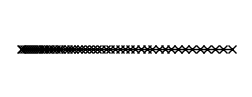

In [100]:
fig,ax=plt.subplots(1,1,figsize=(3,1))
plt.axis('off')
ax.plot(sol.vozlisca[:,0], sol.vozlisca[:,1], 'kx-')
# plt.savefig(f'./slike/vozlisca_zgost_rob.pdf', bbox_inches='tight')

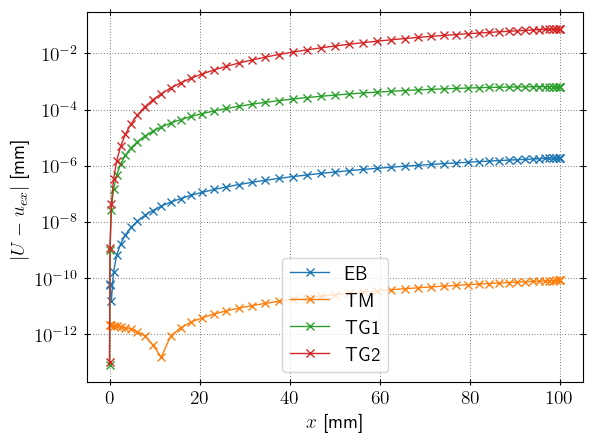

In [ ]:
ratio=10000
fig,ax=plt.subplots(1,1)

for KE in ['EB', 'TM', 'TG1', 'TG2']:
    sol = solver(Ne=50, Nh=100, N_iter=None, tol=1)

    sol.elastic=True
    sol.KE = KE

    # x = sol.zgostitev1(ratio)
    x = sol.zgostitev2()

    sol.discretization(x)
    sol.elastic_solve()
    sol.U, sol.Θ = sol.u.reshape(sol.vozlisca.shape).T
    u_ex,phi_ex,M_ex,T_ex=sol.analitično()

    ax.plot(sol.vozlisca[:,0], np.abs(sol.U-u_ex), 'x-', label=sol.KE)
# plt.legend(title=f'ratio = {ratio:.5g}', loc='best')
plt.legend()
plt.yscale('log')
plt.xlabel(r'$x$ [mm]')
plt.ylabel(r'$|U-u_{ex}|$ [mm]')
# plt.savefig(f'./slike/zgost_errx_{ratio}.pdf', bbox_inches='tight')
# plt.savefig(f'./slike/zgost_errx_obojestr.pdf', bbox_inches='tight')

In [11]:
N_list = np.logspace(1,3,50).astype(int) #št. vozlišč za konvergenco
Nh = 10 #št. točk po višini prereza
KE2 = 'TG1' #izbira KE (EB=nosilec Euler-Bernoulli, TG1,TG2,TM-oblike za Timošenko)

u_err = np.zeros_like(N_list, dtype=float)
phi_err = np.zeros_like(N_list, dtype=float)
M_err = np.zeros_like(N_list, dtype=float)
T_err = np.zeros_like(N_list, dtype=float)
u_max=np.zeros_like(N_list, dtype=float)
time = np.zeros_like(N_list, dtype=float)

timer()
for i, N in enumerate(N_list):
    t1=timer()
    sol = solver(N, Nh, N_iter=None, tol=1)
    sol.elastic=True
    sol.KE = KE2
    # x=sol.zgostitev2()
    x=sol.zgostitev1(ratio=5)
    sol.discretization(x)
    # sol.global_loop()
    sol.elastic_solve()
    sol.U, sol.Θ = sol.u.reshape(sol.vozlisca.shape).T
    t2=timer()
    time[i] = t2-t1    
    u_ex,phi_ex,M_ex,T_ex=sol.analitično()

    u_max[i] = abs(np.max(np.abs(u_ex))-np.max(np.abs(sol.U)))
    
    u_err[i] = np.linalg.norm(u_ex-sol.U)/np.linalg.norm(u_ex)
    phi_err[i] = np.linalg.norm(phi_ex-sol.Θ)/np.linalg.norm(phi_ex)
    M_err[i] = np.linalg.norm(M_ex-sol.M)/np.linalg.norm(M_ex)
    T_err[i] = np.linalg.norm(T_ex-sol.T)/np.linalg.norm(T_ex)

In [12]:
KE1 = 'TG1' #izbira KE (EB=nosilec Euler-Bernoulli, TG1,TG2,TM-oblike za Timošenko)

u_err_TG1 = np.zeros_like(N_list, dtype=float)
phi_err_TG1 = np.zeros_like(N_list, dtype=float)
M_err_TG1 = np.zeros_like(N_list, dtype=float)
T_err_TG1 = np.zeros_like(N_list, dtype=float)
u_max_TG1=np.zeros_like(N_list, dtype=float)
time_TG1 = np.zeros_like(N_list, dtype=float)

for i, N in enumerate(N_list):
    t1=timer()
    sol = solver(N, Nh, N_iter=None, tol=1)
    sol.elastic=True
    sol.KE = KE1
    x=np.linspace(0,sol.L,sol.Nv) #enakomerno razporejena vozlišča
    sol.discretization(x)
    sol.elastic_solve()
    sol.U, sol.Θ = sol.u.reshape(sol.vozlisca.shape).T
    t2=timer()
    time_TG1[i] = t2-t1

    u_ex,phi_ex,M_ex,T_ex=sol.analitično()
    u_max_TG1[i] = abs(np.max(np.abs(u_ex))-np.max(np.abs(sol.U)))   
    u_err_TG1[i] = np.linalg.norm(u_ex-sol.U)/np.linalg.norm(u_ex)
    phi_err_TG1[i] = np.linalg.norm(phi_ex-sol.Θ)/np.linalg.norm(phi_ex)
    M_err_TG1[i] = np.linalg.norm(M_ex-sol.M)/np.linalg.norm(M_ex)
    T_err_TG1[i] = np.linalg.norm(T_ex-sol.T)/np.linalg.norm(T_ex)

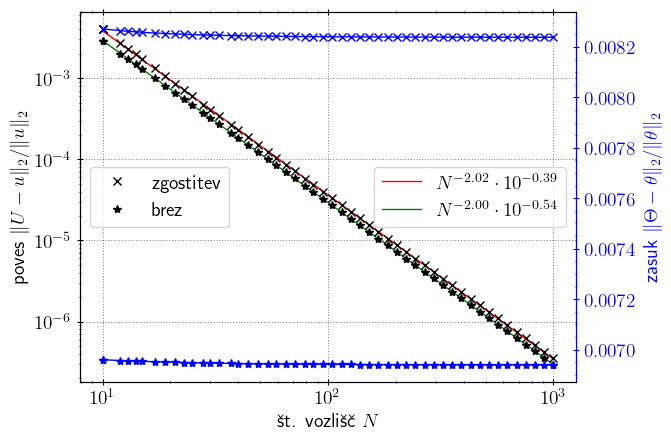

In [13]:
k,n=linfit(np.log10(N_list), np.log10(u_err))
ktg1,ntg1=linfit(np.log10(N_list), np.log10(u_err_TG1))

fig,ax=plt.subplots()
ax.loglog(N_list, N_list**k * 10**n, 'r-', label=f'$N^{{{k:.2f}}}\cdot 10^{{{n:.2f}}}$')
ax.loglog(N_list, N_list**ktg1 * 10**ntg1, 'g-', label=f'$N^{{{ktg1:.2f}}}\cdot 10^{{{ntg1:.2f}}}$')
l1=ax.loglog(N_list, u_err, 'kx')
l2=ax.loglog(N_list, u_err_TG1, 'k*')
ax.minorticks_on()
# ax.grid(which='both', axis='both')
ax.set_xlabel('št. vozlišč $N$')
ax.set_ylabel(r'poves $\|U-u\|_2/\|u\|_2$')
ax.grid(True, which='major')
ax.legend(loc='center right')

ax1 = ax.twinx()
ax1.plot(N_list, phi_err, 'bx-', label='$\phi$')
ax1.plot(N_list, phi_err_TG1, 'b*-', label='$\phi$')
ax1.set_ylabel(r'zasuk $\|\Theta-\theta\|_2/\|\theta\|_2$', color='b')
# ax1.set_yscale('log')
ax1.minorticks_on()
ax1.tick_params(axis='y', which='both', colors='b')
ax1.spines['right'].set_color('b')
# ax1.spines['right'].set_linewidth(1)
# ax1.grid(which='both', axis='both')
ax1.grid(False)
ax1.legend([l1[0],l2[0]], ['zgostitev','brez'], loc='center left')
# alignYaxes([ax,ax1], [np.max(u_err), 0.2648])
# plt.savefig('./slike/napaka_konv_zgost1.pdf', bbox_inches='tight')

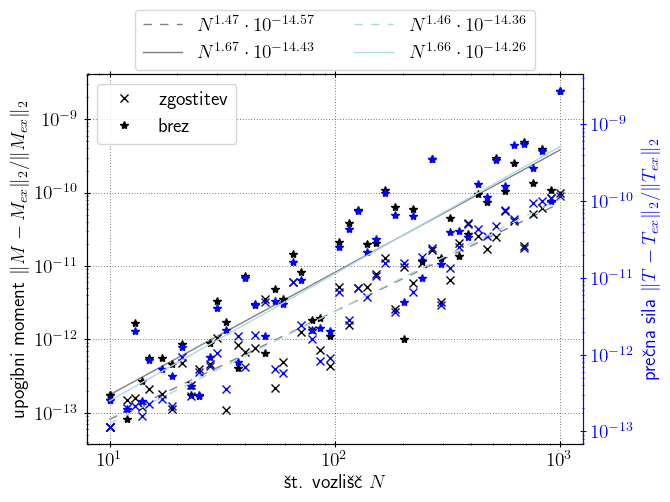

In [14]:
k,n=linfit(np.log10(N_list), np.log10(M_err))
kt,nt=linfit(np.log10(N_list), np.log10(T_err))
ktm,ntm=linfit(np.log10(N_list), np.log10(M_err_TG1))
kttm,nttm=linfit(np.log10(N_list), np.log10(T_err_TG1))

fig,ax=plt.subplots()
l1=ax.loglog(N_list, N_list**k * 10**n, '--', label=f'$N^{{{k:.2f}}}\cdot 10^{{{n:.2f}}}$', c='gray')
l11=ax.loglog(N_list, N_list**ktm * 10**ntm, '-', label=f'$N^{{{ktm:.2f}}}\cdot 10^{{{ntm:.2f}}}$', c='gray')
t1=ax.loglog(N_list, M_err, 'kx')
t2=ax.loglog(N_list, M_err_TG1, 'k*')
ax.minorticks_on()
# ax.grid(which='both', axis='both')
ax.set_xlabel('št. vozlišč $N$')
ax.set_ylabel(r'upogibni moment $\|M-M_{ex}\|_2/\|M_{ex}\|_2$')
ax.grid(True, which='major')

ax1 = ax.twinx()
ax1.loglog(N_list, T_err, 'bx', label='$\phi$')
ax1.loglog(N_list, T_err_TG1, 'b*', label='$\phi$')
ax1.set_ylabel(r'prečna sila $\|T-T_{ex}\|_2/\|T_{ex}\|_2$', color='b')
l2=ax1.loglog(N_list, N_list**kt * 10**nt, '--', label=f'$N^{{{k:.2f}}}\cdot 10^{{{n:.2f}}}$', c='lightblue')
l22=ax1.loglog(N_list, N_list**kttm * 10**nttm, '-', label=f'$N^{{{kttm:.2f}}}\cdot 10^{{{nttm:.2f}}}$', c='lightblue')
ax1.minorticks_on()
ax1.tick_params(axis='y', which='both', colors='b')
ax1.spines['right'].set_color('b')
# ax1.spines['right'].set_linewidth(1)
# ax1.grid(which='both', axis='both')
ax1.grid(False)
ax.legend((l1[0], l11[0], l2[0], l22[0]), (f'$N^{{{k:.2f}}}\cdot 10^{{{n:.2f}}}$', f'$N^{{{ktm:.2f}}}\cdot 10^{{{ntm:.2f}}}$', f'$N^{{{kt:.2f}}}\cdot 10^{{{nt:.2f}}}$', f'$N^{{{kttm:.2f}}}\cdot 10^{{{nttm:.2f}}}$'), loc='upper center', ncols=2, bbox_to_anchor=(0.5,1.2))
ax1.legend([t1[0],t2[0]], ['zgostitev','brez'], loc='upper left')
# plt.savefig('./slike/napaka_konv_MT_zgost1.pdf', bbox_inches='tight')

In [74]:
ratio_list = np.linspace(1+1e-9, 10, 100)
N = 1000 #št. vozlišč
Nh = 10 #št. točk po višini prereza
KE = 'TG1' #izbira KE (EB=nosilec Euler-Bernoulli, TG1,TG2,TM-oblike za Timošenko)

u_err = np.zeros_like(ratio_list, dtype=float)
phi_err = np.zeros_like(ratio_list, dtype=float)
M_err = np.zeros_like(ratio_list, dtype=float)
T_err = np.zeros_like(ratio_list, dtype=float)
u_max=np.zeros_like(ratio_list, dtype=float)
time = np.zeros_like(ratio_list, dtype=float)

timer()
for i, ratio in enumerate(ratio_list):
    t1=timer()
    sol = solver(N, Nh, N_iter=None, tol=1)
    sol.elastic=True
    sol.KE = KE
    x=sol.zgostitev1(ratio)
    sol.discretization(x)
    # sol.global_loop()
    sol.elastic_solve()
    sol.U, sol.Θ = sol.u.reshape(sol.vozlisca.shape).T
    t2=timer()
    time[i] = t2-t1    
    u_ex,phi_ex,M_ex,T_ex=sol.analitično()

    u_max[i] = abs(np.max(np.abs(u_ex))-np.max(np.abs(sol.U)))
    
    u_err[i] = np.linalg.norm(u_ex-sol.U)/np.linalg.norm(u_ex)
    phi_err[i] = np.linalg.norm(phi_ex-sol.Θ)/np.linalg.norm(phi_ex)
    M_err[i] = np.linalg.norm(M_ex-sol.M)/np.linalg.norm(M_ex)
    T_err[i] = np.linalg.norm(T_ex-sol.T)/np.linalg.norm(T_ex)

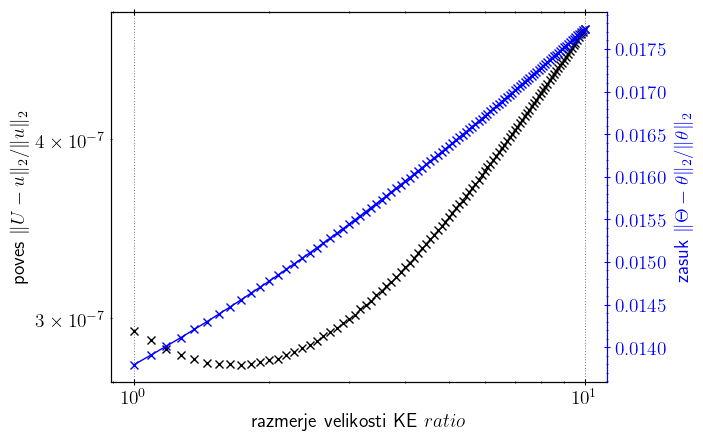

In [ ]:
k,n=linfit(np.log10(ratio_list), np.log10(u_err))
kt,nt=linfit(np.log10(ratio_list), np.log10(phi_err))

fig,ax=plt.subplots()
# t1=ax.loglog(ratio_list, ratio_list**k * 10**n, 'r-', label=f'$N^{{{k:.2f}}}\cdot 10^{{{n:.2f}}}$')
l1=ax.loglog(ratio_list, u_err, 'kx')
ax.minorticks_on()
# ax.grid(which='both', axis='both')
ax.set_xlabel('razmerje velikosti KE $ratio$')
ax.set_ylabel(r'poves $\|U-u\|_2/\|u\|_2$')
ax.grid(True, which='major')
# ax.set_xscale('linear')

ax1 = ax.twinx()
# t2=ax1.loglog(ratio_list, ratio_list**kt * 10**nt, '-', label=f'$N^{{{kt:.2f}}}\cdot 10^{{{nt:.2f}}}$', c='lightblue')
ax1.plot(ratio_list, phi_err, 'bx-', label='$\phi$')
ax1.set_ylabel(r'zasuk $\|\Theta-\theta\|_2/\|\theta\|_2$', color='b')
# ax1.set_yscale('log')
ax1.minorticks_on()
ax1.tick_params(axis='y', which='both', colors='b')
ax1.spines['right'].set_color('b')
# ax1.spines['right'].set_linewidth(1)
# ax1.grid(which='both', axis='both')
ax1.grid(False)
# ax.legend((t1[0], t2[0]), (f'$N^{{{k:.2f}}}\cdot 10^{{{n:.2f}}}$', f'$N^{{{kt:.2f}}}\cdot 10^{{{nt:.2f}}}$'), loc='best')
# plt.savefig('./slike/napaka_ratio.pdf', bbox_inches='tight')

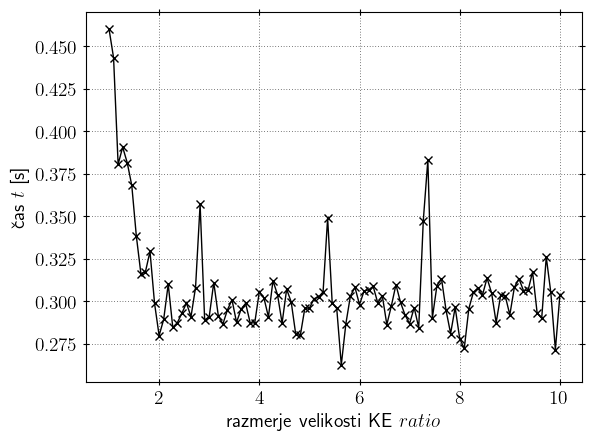

In [ ]:
plt.plot(ratio_list, time, 'kx-')
plt.xlabel('razmerje velikosti KE $ratio$')
plt.ylabel('čas $t$ [s]')
# plt.savefig('./slike/cas_ratio.pdf', bbox_inches='tight')

# notranje veličine

In [261]:
Nv = 30 # št. vozlišč
Ne = Nv-1 #št el
Nh = 30 # št. točk po višini prereza

sol = solver(Ne, Nh, N_iter=None, tol=1)
sol.L=10
sol.KE = 'TG1'
sol.elastic=True

x=np.linspace(0,sol.L,sol.Nv) #enakomerno razporejena vozlišča

sol.discretization(x)

# sol.global_loop()
sol.elastic_solve()

sol.U, sol.Θ = sol.u.reshape(sol.vozlisca.shape).T
sol.u_integ = np.array([(sol.U[i] + sol.U[i+1])/2 for i in range(sol.Ne)]) #poves lin interpoliran na sredini KE

U_all = np.repeat(sol.U,sol.Nh).reshape(sol.Nv,sol.Nh) #poves razširjen na cel prerez
X_cor = np.transpose([-y*sol.Θ for y in sol.y_list]) #popravek zaradi EB predpostavke o planosti prereza
sol.X_defor, sol.Y_defor = sol.X_defor + X_cor, sol.Y_defor + U_all

(M_y_MKE, T_y_MKE) = sol.internal_vars()
sol.internal_f()

u_ex,phi_ex,M_ex,T_ex = sol.analitično()
# np.linalg.norm(sol.U-u_ex)/np.linalg.norm(u_ex), np.linalg.norm(sol.U-u_ex), np.linalg.norm(sol.U), np.linalg.norm(sol.Θ-phi_ex)/np.linalg.norm(phi_ex), np.linalg.norm(sol.Θ-phi_ex), np.linalg.norm(sol.Θ)

In [262]:
x= [0, 0.5, 1]
x2=[]
M2=[]
for i,xi in enumerate(x):
    M2i=sol.M_bend(xi)
    M2.append(M2i)
    x2.append(sol.vozlisca[:-1,0] + xi*sol.L_ke)
M2=np.transpose(M2)
# x2=np.transpose(x2)
# plt.plot(x2.ravel(),M2.ravel(), 'x-') #velja le za EB!!!
# plt.plot(sol.integ_tocke[:,0], sol.M, 'o') #velja za EB in timo!

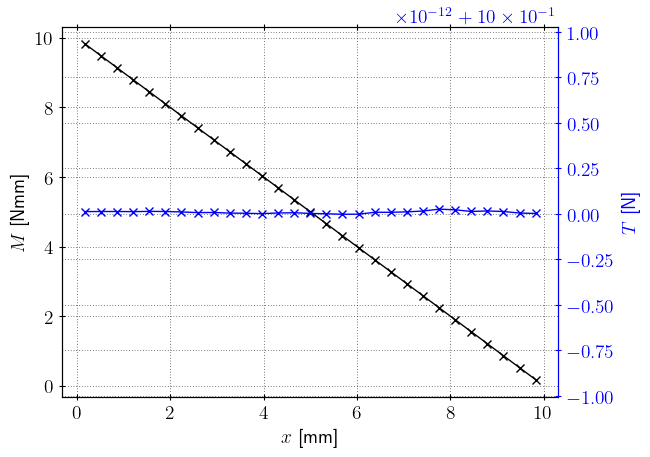

In [263]:
fig,ax=plt.subplots(1,1)
ax1=ax.twinx()
ax.plot(sol.integ_tocke[:,0], sol.M, 'kx-', label='$M$')
ax1.plot(sol.integ_tocke[:,0], sol.T, 'bx-', label='$T$')
ax.set_xlabel('$x$ [mm]')
ax.set_ylabel('$M$ [Nmm]')
ax1.set_ylabel('$T$ [N]', color='b')
ax1.tick_params(axis='y', which='both', colors='b')
ax1.spines['right'].set_color('b')
# ax1.set_ylim([1+88e-13, 1+93e-13])
# ax1.set_ylim([1-2e-12, 1+1e-13])
# alignYaxes([ax,ax1], [100, 1])
# plt.savefig(f'./slike/MT_{sol.KE}_L{sol.L}.pdf', bbox_inches='tight')

Text(0, 0.5, 'največja deformacija $\\varepsilon$ [\\%]')

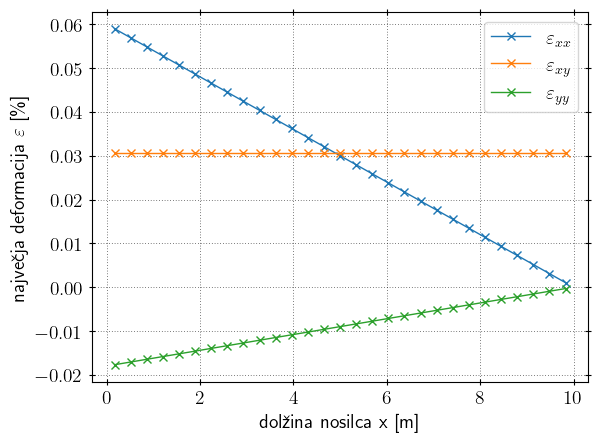

In [264]:
ty=-1
plt.plot(sol.integ_tocke[:,0], -sol.ε[:,ty,0,0]*100, 'x-', label='$\\varepsilon_{xx}$')
plt.plot(sol.integ_tocke[:,0], -sol.ε[:,ty,1,0]*100, 'x-', label='$\\varepsilon_{xy}$')
plt.plot(sol.integ_tocke[:,0], -sol.ε[:,ty,1,1]*100, 'x-', label='$\\varepsilon_{yy}$')
plt.legend()
plt.xlabel('dolžina nosilca x [m]')
plt.ylabel('največja deformacija $\\varepsilon$ [\\%]')
# plt.savefig(f'./slike/deform_{sol.KE}.pdf', bbox_inches='tight')

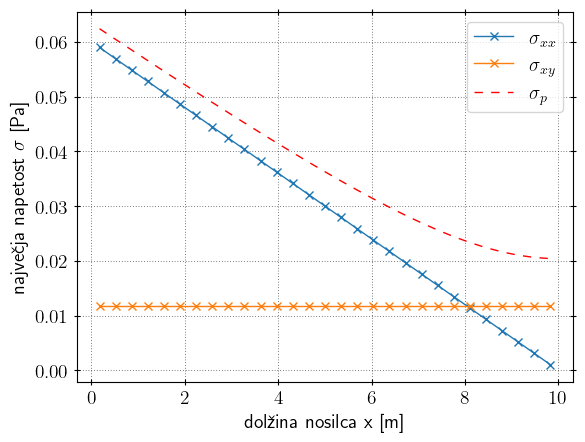

In [ ]:
ty=-1
plt.plot(sol.integ_tocke[:,0], -sol.σ[:,ty,0,0], 'x-', label='$\\sigma_{xx}$')
plt.plot(sol.integ_tocke[:,0], -sol.σ[:,ty,1,0], 'x-', label='$\\sigma_{xy}$')
plt.plot(sol.integ_tocke[:,0], sol.q[:,ty], 'r--', label='$\\sigma_p$')
plt.legend()
plt.xlabel('dolžina nosilca x [m]')
plt.ylabel('največja napetost $\sigma$ [Pa]')
# plt.savefig(f'./slike/napetosti_{sol.KE}.pdf', bbox_inches='tight')

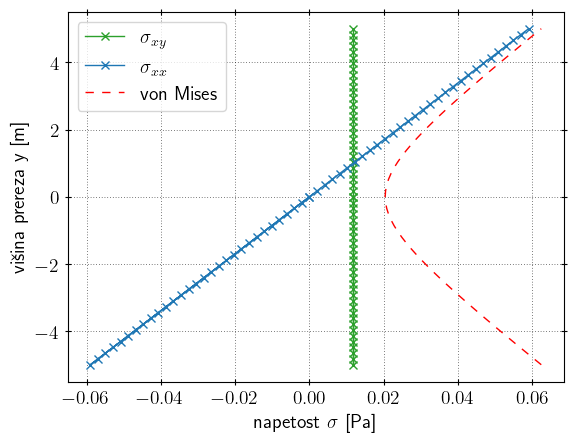

In [ ]:
xi=0 #cross sec
sxx=np.hstack([sol.σ[xi,:,0,0], -sol.σ[xi,:,0,0]])
sxy=np.hstack([sol.σ[xi,:,1,0], sol.σ[xi,:,1,0]])
sm=np.hstack([sol.q[xi,::-1], sol.q[xi,::]])
csec=np.hstack([-sol.y_list, sol.y_list])
csecm=np.hstack([-sol.y_list[::-1], sol.y_list[::]])
if sol.KE != 'EB': plt.plot(np.abs(sxy), csec, 'C2x-', label='$\\sigma_{xy}$')
# plt.plot(np.abs(sxy)+np.abs(sxx), csec, 'x-', label='$\\sigma_{xy}+\\sigma_{xx}$')
plt.plot(sxx, csec, 'C0x-', label='$\\sigma_{xx}$')
plt.plot(sm, csecm, 'r--', label='von Mises')
plt.legend()
plt.xlabel('napetost $\sigma$ [Pa]')
plt.ylabel('višina prereza y [m]')
# plt.savefig(f'./slike/napetosti_prerez_{sol.KE}.pdf', bbox_inches='tight')

## test stress

In [20]:
y=sol.h/2
epsilon_xx = sol.strain_EB()
epsilon_xx = epsilon_xx[:,-1,0,0]

exx_MKE,eyy_MKE,exy_MKE=sol.epsilon_MKE(y)
exx_MKR,eyy_MKR,exy_MKR=sol.epsilon_MKR(y)

xx_MKE,yy_MKE,xy_MKE=sol.sigma(y, method='MKE')
xx_MKR,yy_MKR,xy_MKR=sol.sigma(y, method='MKR')

print(np.linalg.norm(xx_MKE-xx_MKR), np.linalg.norm(yy_MKE-yy_MKR), np.linalg.norm(xy_MKE-xy_MKR))
print(xx_MKE.shape, xx_MKR.shape, yy_MKE.shape, yy_MKR.shape, xy_MKE.shape, xy_MKR.shape)
print(exx_MKE.shape, exx_MKR.shape, eyy_MKE.shape, eyy_MKR.shape, exy_MKE.shape, exy_MKR.shape)
print(epsilon_xx.shape)

2.2825424421031095 0.12820512820515087 2.2256375809505267
(9, 1) (9,) (9, 1) (9,) (9, 1) (9,)
(9, 1) (9,) (9, 1) (9,) (9, 1) (9,)
(9,)


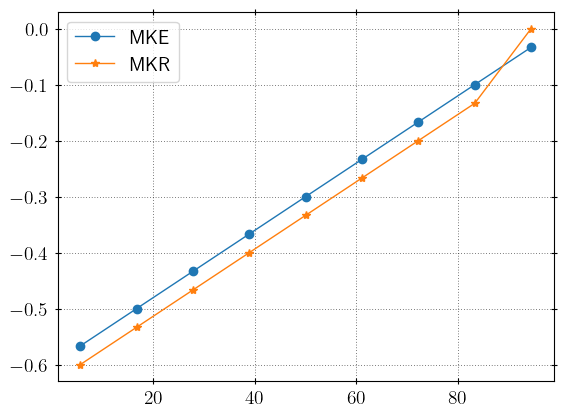

In [21]:
plt.plot(sol.integ_tocke[:,0], xx_MKE, 'o-', label='MKE')
plt.plot(sol.integ_tocke[:,0], xx_MKR, '*-', label='MKR')
plt.legend();

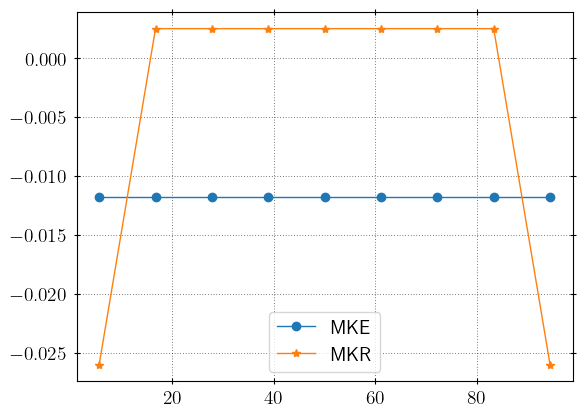

In [22]:
plt.plot(sol.integ_tocke[:,0], yy_MKE, 'o-', label='MKE')
plt.plot(sol.integ_tocke[:,0], yy_MKR, '*-', label='MKR')
plt.legend();

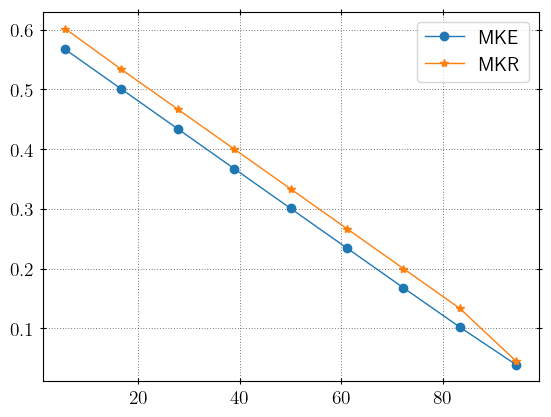

In [23]:
plt.plot(sol.integ_tocke[:,0], xy_MKE, 'o-', label='MKE')
plt.plot(sol.integ_tocke[:,0], xy_MKR, '*-', label='MKR')
plt.legend()

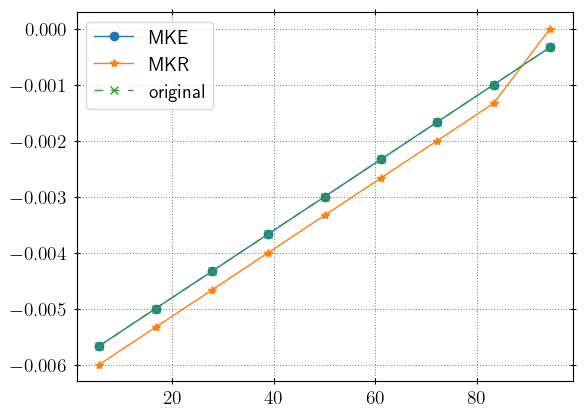

In [24]:
plt.plot(sol.integ_tocke[:,0], exx_MKE, 'o-', label='MKE')
plt.plot(sol.integ_tocke[:,0], exx_MKR, '*-', label='MKR')
plt.plot(sol.integ_tocke[:,0], epsilon_xx, 'x--', label='original')
plt.legend();

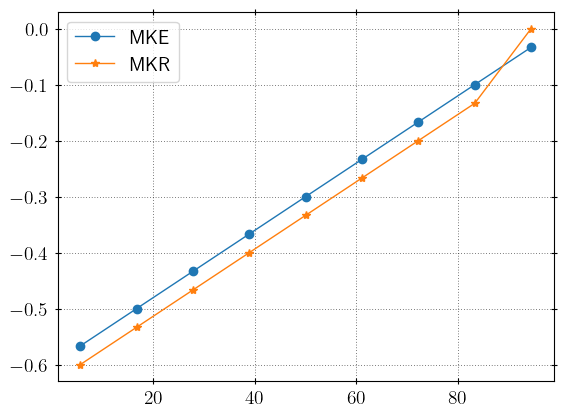

In [25]:
plt.plot(sol.integ_tocke[:,0], xx_MKE, 'o-', label='MKE')
plt.plot(sol.integ_tocke[:,0], xx_MKR, '*-', label='MKR')
plt.legend()

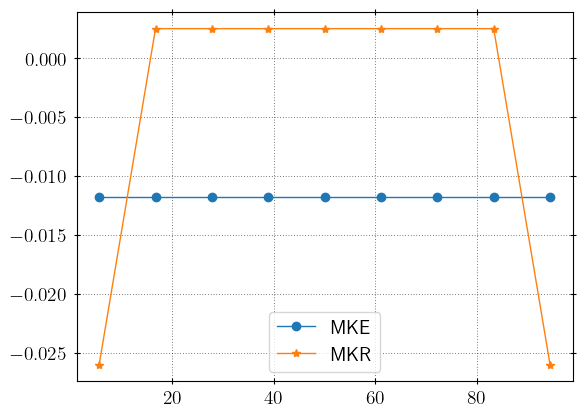

In [26]:
plt.plot(sol.integ_tocke[:,0], yy_MKE, 'o-', label='MKE')
plt.plot(sol.integ_tocke[:,0], yy_MKR, '*-', label='MKR')
plt.legend()#strig xy

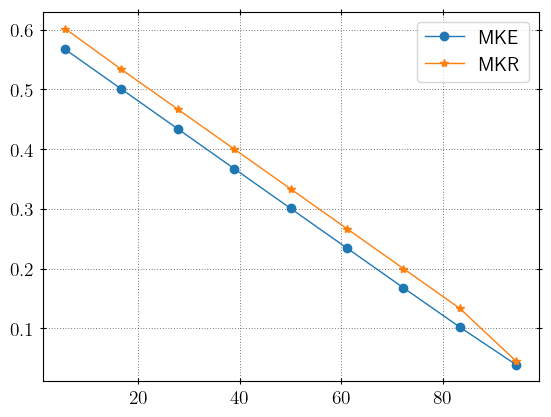

In [27]:
plt.plot(sol.integ_tocke[:,0], xy_MKE, 'o-', label='MKE')
plt.plot(sol.integ_tocke[:,0], xy_MKR, '*-', label='MKR')
plt.legend()#mises